# Estudo de Modelagem de Dados com Regressão Supervisionada
### Previsão do Rendimento (Yield) de Safras Agrícolas a partir de Variáveis Climáticas

**Integrantes do grupo:**

* David Ribeiro Prado de Lacerda — RM 570350
* Giselli Mayumi Takahashi Yokoyama — RM 572690
* João Otávio Moraes — RM 573227
* Pedro Henrique Lacerda — RM 573114
* Renata de Almeida Marinho — RM 569342

**Entrega:** 1 (PBL Fase 5)

## Objetivo
O objetivo deste trabalho é analisar um conjunto de dados agrícolas contendo variáveis climáticas (precipitação, umidade específica, umidade relativa e temperatura) associadas ao rendimento (*Yield*) de quatro culturas — *Cocoa beans*, *Oil palm fruit*, *Rice paddy* e *Rubber natural*. As etapas realizadas são:

1. **Análise Exploratória de Dados (EDA)** — entender a estrutura, a distribuição e as relações entre as variáveis;
2. **Clusterização e detecção de outliers** — identificar padrões/tendências de agrupamento entre as safras e cenários discrepantes;
3. **Modelagem preditiva supervisionada** — treinar e comparar 5 algoritmos de regressão diferentes para prever o *Yield* a partir das condições climáticas e do tipo de cultura, avaliando-os com métricas apropriadas ao problema.


In [1]:
# =====================================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# =====================================================================
import matplotlib.pyplot as plt      # geração de gráficos
import numpy as np                   # operações numéricas
import pandas as pd                  # manipulação de dados tabulares
import seaborn as sns                # gráficos estatísticos

from sklearn.cluster import KMeans                              # clusterização
from sklearn.compose import ColumnTransformer                   # pré-processamento por coluna
from sklearn.decomposition import PCA                           # redução de dimensionalidade p/ visualização
from sklearn.ensemble import IsolationForest, RandomForestRegressor  # outliers e modelo 5
from sklearn.linear_model import LinearRegression                # modelo 1
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor                # modelo 2
from sklearn.pipeline import Pipeline                            # boas práticas: evitar vazamento de dados
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # codificação e padronização
from sklearn.svm import SVR                                      # modelo 3
from sklearn.tree import DecisionTreeRegressor                   # modelo 4

# Configurações visuais padrão para todos os gráficos do notebook
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # semente fixa para reprodutibilidade em todas as etapas


In [2]:
# =====================================================================
# 2. CARGA E INSPEÇÃO INICIAL DA BASE DE DADOS
# =====================================================================
df = pd.read_csv("crop_yield.csv", skipinitialspace=True)  # skipinitialspace remove espaços após vírgulas

print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas\n")
display(df.head())

print("\n--- Tipos de dados ---")
print(df.dtypes)

print("\n--- Valores nulos por coluna ---")
print(df.isnull().sum())

print(f"\n--- Linhas duplicadas: {df.duplicated().sum()} ---")

print("\n--- Culturas (Crop) presentes na base ---")
display(df["Crop"].value_counts().to_frame(name="Nº de registros"))


,Crop,Precipitation (mm day-1),Specific Humidity at 2 Meters (g/kg),Relative Humidity at 2 Meters (%),Temperature at 2 Meters (C),Yield
0,"Cocoa, beans",2248.92,17.72,83.40,26.01,11560
1,"Cocoa, beans",1938.42,17.54,82.11,26.11,11253
2,"Cocoa, beans",2301.54,17.81,82.79,26.24,9456
3,"Cocoa, beans",2592.35,17.61,85.07,25.56,9321
4,"Cocoa, beans",2344.72,17.61,84.12,25.76,8800


,Nº de registros
Crop,
"Cocoa, beans",39
Oil palm fruit,39
"Rice, paddy",39
"Rubber, natural",39


Dimensões do dataset: 156 linhas x 6 colunas


--- Tipos de dados ---
Crop                                        str
Precipitation (mm day-1)                float64
Specific Humidity at 2 Meters (g/kg)    float64
Relative Humidity at 2 Meters (%)       float64
Temperature at 2 Meters (C)             float64
Yield                                     int64
dtype: object

--- Valores nulos por coluna ---
Crop                                    0
Precipitation (mm day-1)                0
Specific Humidity at 2 Meters (g/kg)    0
Relative Humidity at 2 Meters (%)       0
Temperature at 2 Meters (C)             0
Yield                                   0
dtype: int64

--- Linhas duplicadas: 0 ---

--- Culturas (Crop) presentes na base ---


## 1. Análise Exploratória de Dados (EDA)

A base contém **156 registros** e **6 colunas**: uma variável categórica (`Crop`, o tipo de cultura), quatro variáveis climáticas numéricas (`Precipitation`, `Specific Humidity`, `Relative Humidity`, `Temperature`) e a variável-alvo `Yield` (rendimento da safra). Não há valores nulos nem linhas duplicadas, então nenhum tratamento de limpeza adicional foi necessário.

A base está **perfeitamente balanceada entre as 4 culturas** (39 registros cada: *Cocoa beans*, *Oil palm fruit*, *Rice paddy*, *Rubber natural*), o que é positivo para a modelagem, pois evita viés de classes desbalanceadas.


,count,mean,std,min,25%,50%,75%,max
Precipitation (mm day-1),156.0,2486.498974,289.457914,1934.62,2302.99,2424.55,2718.08,3085.79
Specific Humidity at 2 Meters (g/kg),156.0,18.203077,0.293923,17.54,18.03,18.27,18.40,18.70
Relative Humidity at 2 Meters (%),156.0,84.737692,0.996226,82.11,84.12,84.85,85.51,86.10
Temperature at 2 Meters (C),156.0,26.183590,0.261050,25.56,26.02,26.13,26.30,26.81
Yield,156.0,56153.096154,70421.958897,5249.00,8327.75,18871.00,67518.75,203399.00


--- Resumo estatístico das variáveis numéricas ---


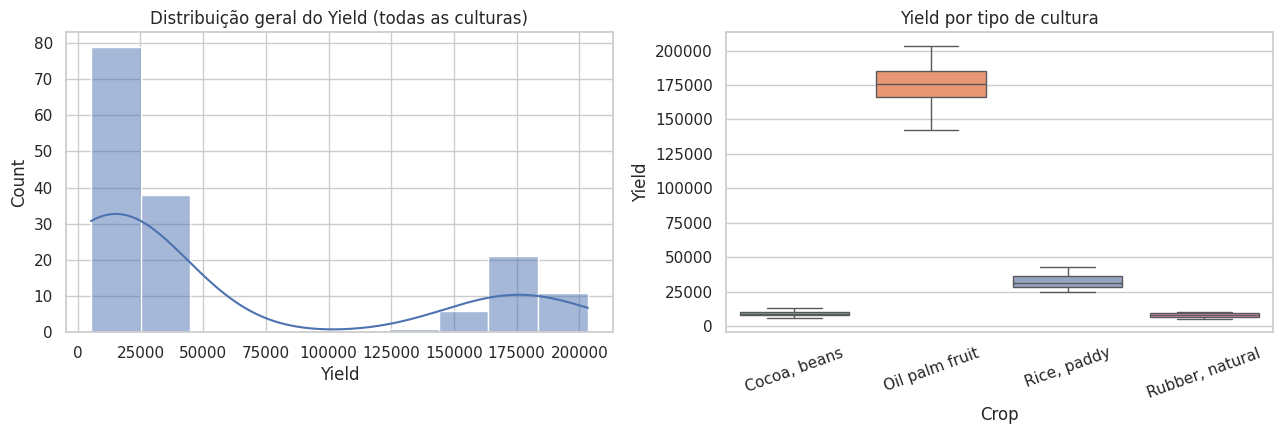

In [3]:
# =====================================================================
# 3. ESTATÍSTICAS DESCRITIVAS E DISTRIBUIÇÃO DAS VARIÁVEIS
# =====================================================================
numeric_features = [
    "Precipitation (mm day-1)",
    "Specific Humidity at 2 Meters (g/kg)",
    "Relative Humidity at 2 Meters (%)",
    "Temperature at 2 Meters (C)",
]
categorical_features = ["Crop"]

print("--- Resumo estatístico das variáveis numéricas ---")
display(df[numeric_features + ["Yield"]].describe().T)

# Histograma da variável-alvo (Yield) para observar sua distribuição geral
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["Yield"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribuição geral do Yield (todas as culturas)")

# Boxplot do Yield por cultura: evidencia que a escala do rendimento
# depende fortemente do tipo de cultura
sns.boxplot(data=df, x="Crop", y="Yield", hue="Crop", ax=axes[1], palette="Set2", legend=False)
axes[1].set_title("Yield por tipo de cultura")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


**Achado:** a distribuição do *Yield* é fortemente assimétrica à direita (à esquerda, no histograma geral) e **multimodal**, refletindo o fato de que cada cultura opera em uma escala de produtividade muito distinta — *Rice paddy* atinge rendimentos muito superiores aos de *Cocoa beans*. Isso mostra que a coluna categórica `Crop` **não pode ser descartada** da análise (diferentemente do notebook original desta atividade, que a excluía): ela é a variável que mais explica a variação do rendimento e será mantida em toda a modelagem seguinte, via codificação *one-hot*.


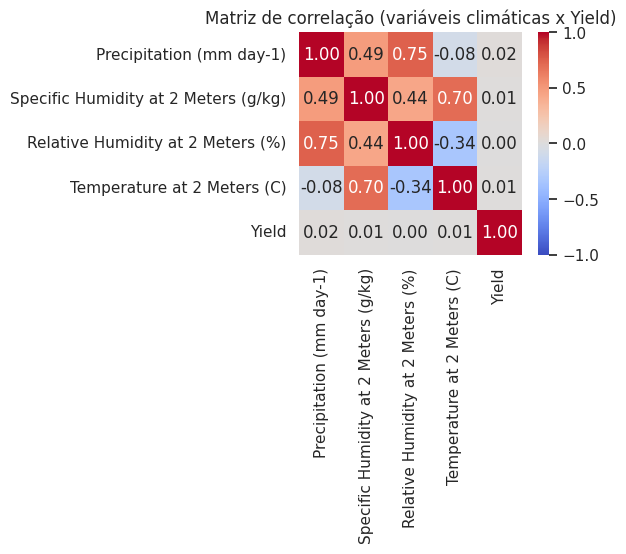

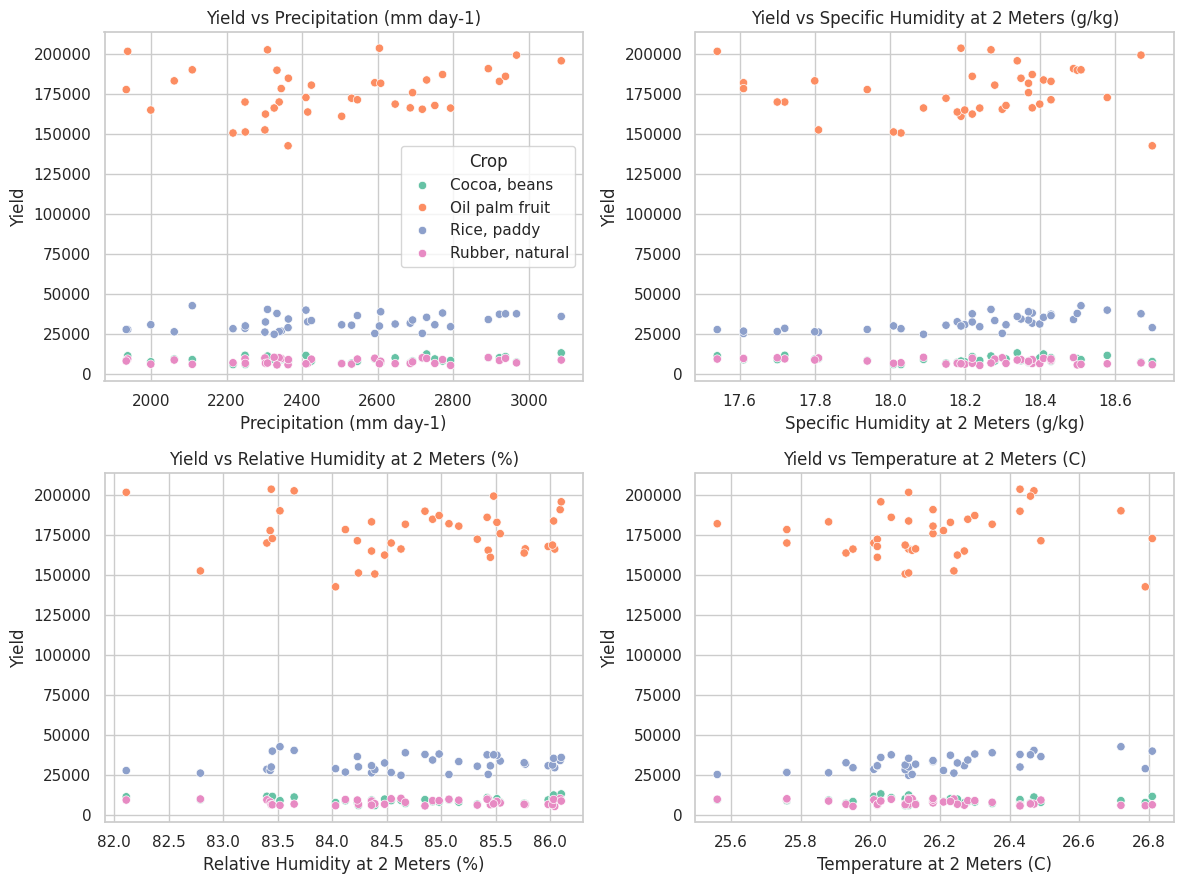

In [4]:
# =====================================================================
# 4. CORRELAÇÃO ENTRE VARIÁVEIS CLIMÁTICAS E RELAÇÃO COM O YIELD
# =====================================================================
plt.figure(figsize=(6.5, 5.5))
corr = df[numeric_features + ["Yield"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1)
plt.title("Matriz de correlação (variáveis climáticas x Yield)")
plt.tight_layout()
plt.show()

# Dispersão de cada variável climática vs Yield, colorida por cultura,
# para inspecionar relações não capturadas pela correlação linear global
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), numeric_features):
    sns.scatterplot(data=df, x=col, y="Yield", hue="Crop", ax=ax, palette="Set2", legend=(col == numeric_features[0]))
    ax.set_title(f"Yield vs {col}")
plt.tight_layout()
plt.show()


**Achado:** a correlação linear *global* entre as variáveis climáticas e o *Yield* é fraca, pois mistura culturas com escalas de produtividade muito diferentes. Já os gráficos de dispersão segmentados por cultura mostram que, **dentro de cada cultura**, existe uma relação mais clara entre clima e rendimento (por exemplo, tendência de queda do rendimento do cacau em condições de umidade relativa mais alta). Essa é uma justificativa adicional para incluir `Crop` como *feature* nos modelos: sem ela, o modelo perderia justamente o sinal mais forte da base.


Melhor k pelo coeficiente de silhueta: 4


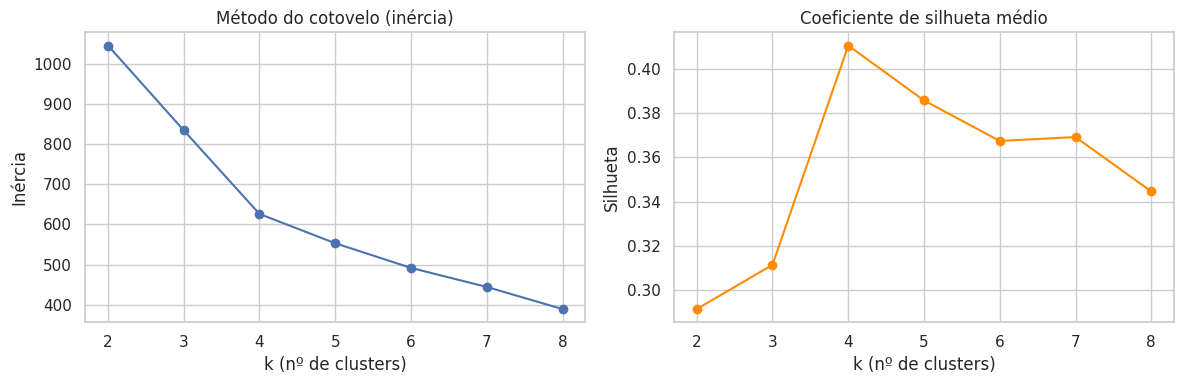

In [5]:
# =====================================================================
# 5. CLUSTERIZAÇÃO — PREPARAÇÃO DOS DADOS
# =====================================================================
# Para a clusterização, usamos as variáveis climáticas + Yield + a cultura
# (codificada em dummies), padronizadas, para que nenhuma variável domine
# o cálculo de distância apenas por ter uma escala numérica maior.
cluster_cols = numeric_features + ["Yield"]
crop_dummies = pd.get_dummies(df["Crop"], prefix="Crop")
cluster_matrix = pd.concat([df[cluster_cols], crop_dummies], axis=1)

scaler_cluster = StandardScaler()
cluster_scaled = scaler_cluster.fit_transform(cluster_matrix)

# Método do cotovelo (inércia) + coeficiente de silhueta para escolher o
# número de clusters (k) de forma orientada por dados, e não arbitrária.
k_range = range(2, 9)
inertias, silhouettes = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(cluster_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(cluster_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_title("Método do cotovelo (inércia)")
axes[0].set_xlabel("k (nº de clusters)")
axes[0].set_ylabel("Inércia")

axes[1].plot(list(k_range), silhouettes, marker="o", color="darkorange")
axes[1].set_title("Coeficiente de silhueta médio")
axes[1].set_xlabel("k (nº de clusters)")
axes[1].set_ylabel("Silhueta")
plt.tight_layout()
plt.show()

best_k = list(k_range)[int(np.argmax(silhouettes))]
print(f"Melhor k pelo coeficiente de silhueta: {best_k}")


,Precipitation (mm day-1),Specific Humidity at 2 Meters (g/kg),Relative Humidity at 2 Meters (%),Temperature at 2 Meters (C),Yield
Cluster,,,,,
0,2486.5,18.2,84.74,26.18,175804.69
1,2486.5,18.2,84.74,26.18,7824.90
2,2486.5,18.2,84.74,26.18,8883.13
3,2486.5,18.2,84.74,26.18,32099.67


Crop,"Cocoa, beans",Oil palm fruit,"Rice, paddy","Rubber, natural"
Cluster,,,,
0,0,39,0,0
1,0,0,0,39
2,39,0,0,0
3,0,0,39,0


Variância explicada pelos 2 componentes do PCA: 49.6%

--- Perfil médio de cada cluster ---

--- Cruzamento Cluster x Cultura ---


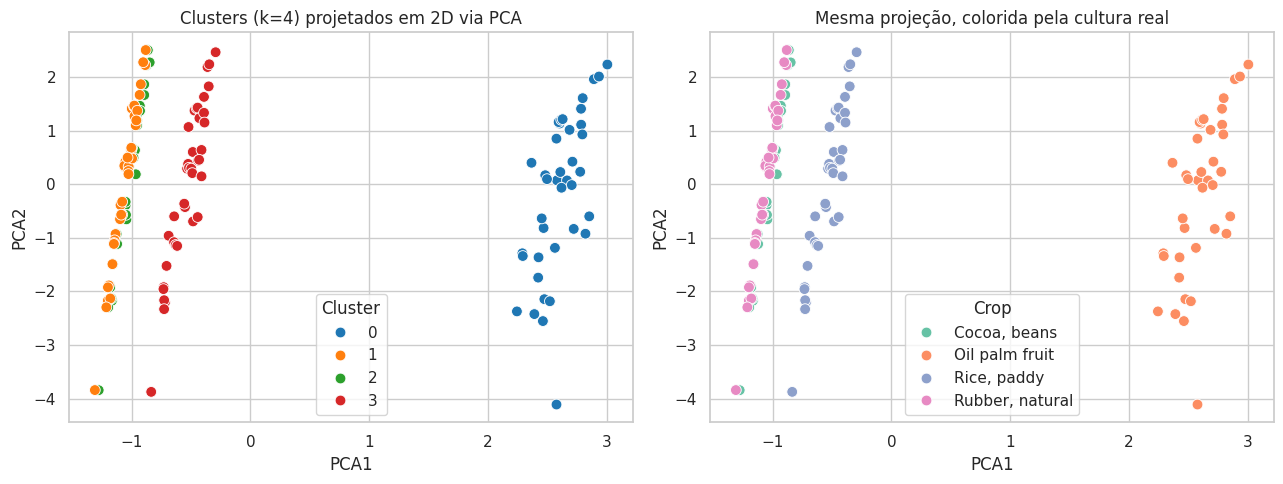

In [6]:
# =====================================================================
# 6. CLUSTERIZAÇÃO — MODELO FINAL E VISUALIZAÇÃO
# =====================================================================
kmeans_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans_final.fit_predict(cluster_scaled)

# Redução para 2 dimensões via PCA apenas para fins de visualização dos clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(cluster_scaled)
df["PCA1"], df["PCA2"] = coords[:, 0], coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Cluster", palette="tab10", ax=axes[0], s=60)
axes[0].set_title(f"Clusters (k={best_k}) projetados em 2D via PCA")

sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Crop", palette="Set2", ax=axes[1], s=60)
axes[1].set_title("Mesma projeção, colorida pela cultura real")
plt.tight_layout()
plt.show()

print(f"Variância explicada pelos 2 componentes do PCA: {pca.explained_variance_ratio_.sum():.1%}\n")

print("--- Perfil médio de cada cluster ---")
display(df.groupby("Cluster")[cluster_cols].mean().round(2))

print("\n--- Cruzamento Cluster x Cultura ---")
display(pd.crosstab(df["Cluster"], df["Crop"]))


**Achado (clusterização):** o coeficiente de silhueta aponta **k=4** como o melhor agrupamento, e o cruzamento *Cluster x Cultura* mostra que os clusters coincidem quase perfeitamente com o tipo de cultura. Isso confirma, de forma não supervisionada, o que já havia sido sugerido na EDA: **a cultura plantada é o fator dominante na tendência de rendimento**, muito mais do que a variação climática registrada dentro da amostra. As variáveis climáticas atuam como um segundo nível de explicação, responsável pela variação de rendimento *dentro* de cada cultura.


,count
Status_Outlier,
Normal,145
Outlier,11


,Nº de outliers
Crop,
Oil palm fruit,5
"Rice, paddy",4
"Cocoa, beans",1
"Rubber, natural",1


--- Contagem geral ---

--- Outliers por cultura ---


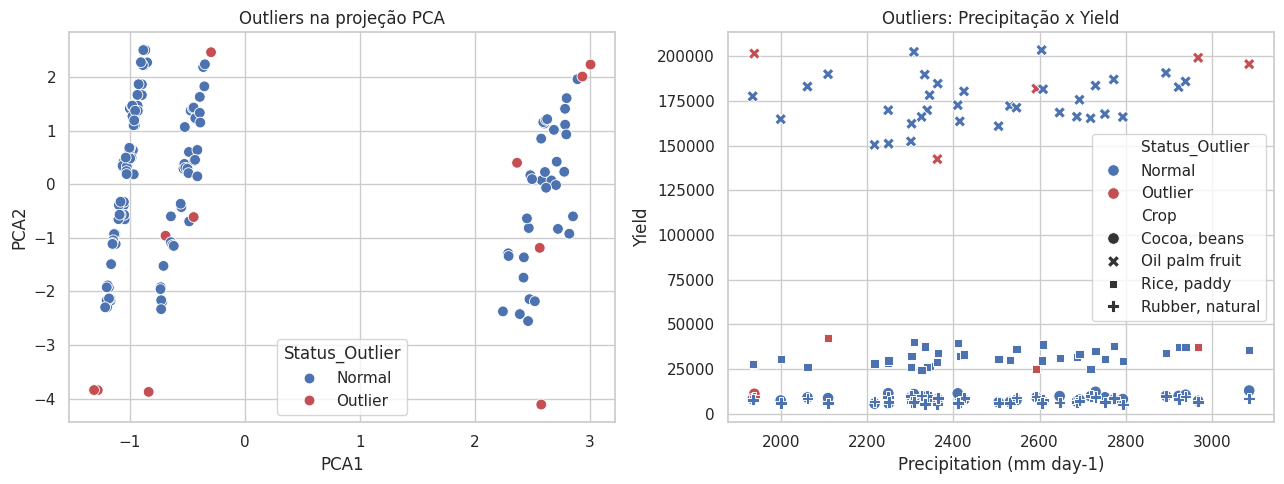

In [7]:
# =====================================================================
# 7. DETECÇÃO DE OUTLIERS (CENÁRIOS DISCREPANTES) — ISOLATION FOREST
# =====================================================================
iso_forest = IsolationForest(contamination=0.07, random_state=RANDOM_STATE)
df["Status_Outlier"] = iso_forest.fit_predict(cluster_scaled)
df["Status_Outlier"] = df["Status_Outlier"].map({1: "Normal", -1: "Outlier"})

print("--- Contagem geral ---")
display(df["Status_Outlier"].value_counts().to_frame())

print("\n--- Outliers por cultura ---")
display(df.loc[df["Status_Outlier"] == "Outlier", "Crop"].value_counts().to_frame(name="Nº de outliers"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Status_Outlier",
                 palette={"Normal": "#4C72B0", "Outlier": "#C44E52"}, ax=axes[0], s=60)
axes[0].set_title("Outliers na projeção PCA")

sns.scatterplot(data=df, x="Precipitation (mm day-1)", y="Yield", hue="Status_Outlier", style="Crop",
                 palette={"Normal": "#4C72B0", "Outlier": "#C44E52"}, ax=axes[1], s=70)
axes[1].set_title("Outliers: Precipitação x Yield")
plt.tight_layout()
plt.show()


**Achado (outliers):** com uma taxa de contaminação de 7%, o *Isolation Forest* isolou **11 safras** como cenários discrepantes, concentradas principalmente em *Oil palm fruit* e *Rice paddy* — justamente as culturas com maior amplitude/variância de rendimento na base. Esses pontos representam safras em que a combinação de clima observada levou a um rendimento muito acima ou abaixo do padrão daquela cultura, e merecem atenção especial em uma eventual auditoria dos dados (por exemplo, para verificar se refletem eventos climáticos extremos reais ou erros de registro).


## 2. Modelagem Preditiva Supervisionada

Nesta seção treinamos **5 algoritmos de regressão diferentes** para prever o `Yield` a partir das 4 variáveis climáticas e da cultura (`Crop`). Boas práticas adotadas:

* **Separação treino/teste (75%/25%)** feita antes de qualquer ajuste de escala, evitando vazamento de dados (*data leakage*);
* **`ColumnTransformer` + `Pipeline`**: o pré-processamento (padronização das variáveis numéricas e *one-hot encoding* de `Crop`) é encapsulado dentro do pipeline de cada modelo, garantindo que o mesmo processo seja aplicado de forma consistente ao treino, ao teste e à validação cruzada;
* **Validação cruzada (K-Fold, k=5)** além da métrica no conjunto de teste único, para obter uma estimativa mais robusta do desempenho, já que a base é pequena (156 registros);
* **Seleção de hiperparâmetro para o KNN** (número de vizinhos) e ajuste do parâmetro `C` do SVR por validação cruzada no conjunto de treino, evitando otimizar diretamente sobre o conjunto de teste.


In [8]:
# =====================================================================
# 8. PREPARAÇÃO DOS DADOS PARA MODELAGEM
# =====================================================================
X = df[numeric_features + categorical_features]
y = df["Yield"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

# Pré-processador único, reaproveitado por todos os pipelines de modelo:
# - variáveis numéricas: padronização (média 0, desvio 1)
# - variável categórica Crop: one-hot encoding (descartando a 1ª categoria p/ evitar colinearidade)
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
])

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")


Treino: 117 amostras | Teste: 39 amostras


In [9]:
# =====================================================================
# 9. SELEÇÃO DE HIPERPARÂMETROS (KNN e SVR) POR VALIDAÇÃO CRUZADA NO TREINO
# =====================================================================
# --- KNN: escolher o nº de vizinhos que maximiza o R² médio em CV ---
knn_scores = {}
for k in [2, 3, 4, 5, 7, 9]:
    pipe = Pipeline([("prep", preprocessor), ("model", KNeighborsRegressor(n_neighbors=k))])
    knn_scores[k] = cross_val_score(pipe, X_train, y_train, cv=kfold, scoring="r2").mean()
best_k_knn = max(knn_scores, key=knn_scores.get)
print("R² médio (CV) por k no KNN:", {k: round(v, 3) for k, v in knn_scores.items()})
print(f"-> melhor k: {best_k_knn}")

# --- SVR: como o Yield tem escala muito ampla (milhares a centenas de milhares),
# valores padrão de C/epsilon deixam o modelo praticamente incapaz de aprender.
# Testamos um pequeno grid de C (epsilon fixo, proporcional à escala do alvo) ---
svr_scores = {}
for C in [1_000, 10_000, 100_000, 1_000_000]:
    pipe = Pipeline([("prep", preprocessor), ("model", SVR(kernel="rbf", C=C, epsilon=100))])
    svr_scores[C] = cross_val_score(pipe, X_train, y_train, cv=kfold, scoring="r2").mean()
best_C_svr = max(svr_scores, key=svr_scores.get)
print("\nR² médio (CV) por C no SVR:", {c: round(v, 3) for c, v in svr_scores.items()})
print(f"-> melhor C: {best_C_svr}")


R² médio (CV) por k no KNN: {2: np.float64(0.624), 3: np.float64(0.679), 4: np.float64(0.651), 5: np.float64(0.611), 7: np.float64(0.538), 9: np.float64(0.498)}
-> melhor k: 3

R² médio (CV) por C no SVR: {1000: np.float64(-0.281), 10000: np.float64(0.091), 100000: np.float64(0.848), 1000000: np.float64(0.947)}
-> melhor C: 1000000


In [10]:
# =====================================================================
# 10. TREINO E AVALIAÇÃO DOS 5 MODELOS DE REGRESSÃO
# =====================================================================
models = {
    "1. Regressão Linear Múltipla": LinearRegression(),
    f"2. KNN Regressor (k={best_k_knn})": KNeighborsRegressor(n_neighbors=best_k_knn),
    f"3. SVR (kernel RBF, C={best_C_svr})": SVR(kernel="rbf", C=best_C_svr, epsilon=100),
    "4. Árvore de Decisão": DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=6),
    "5. Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_estimators=300, max_depth=8),
}

results = []
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)                     # treino
    pred_test = pipe.predict(X_test)                # previsão no conjunto de teste (holdout)
    cv_r2 = cross_val_score(pipe, X, y, cv=kfold, scoring="r2")  # validação cruzada na base toda

    results.append({
        "Modelo": name,
        "MAE (teste)": mean_absolute_error(y_test, pred_test),
        "RMSE (teste)": np.sqrt(mean_squared_error(y_test, pred_test)),
        "R² (teste)": r2_score(y_test, pred_test),
        "R² médio (CV, k=5)": cv_r2.mean(),
        "Desvio-padrão R² (CV)": cv_r2.std(),
    })
    fitted_pipelines[name] = (pipe, pred_test)

df_ranking = pd.DataFrame(results).sort_values("R² médio (CV, k=5)", ascending=False).reset_index(drop=True)
print("--- RANKING DOS MODELOS (ordenado pelo R² médio em validação cruzada) ---")
display(df_ranking.round(4))


,Modelo,MAE (teste),RMSE (teste),R² (teste),"R² médio (CV, k=5)",Desvio-padrão R² (CV)
0,5. Random Forest,4434.6848,9323.9361,0.9810,0.9880,0.0062
1,1. Regressão Linear Múltipla,4391.1868,7943.2516,0.9862,0.9870,0.0052
2,4. Árvore de Decisão,5326.2695,10255.3846,0.9770,0.9862,0.0071
3,"3. SVR (kernel RBF, C=1000000)",9031.5499,15807.7443,0.9453,0.9552,0.0245
4,2. KNN Regressor (k=3),16843.3077,33492.0165,0.7546,0.6995,0.0654


--- RANKING DOS MODELOS (ordenado pelo R² médio em validação cruzada) ---


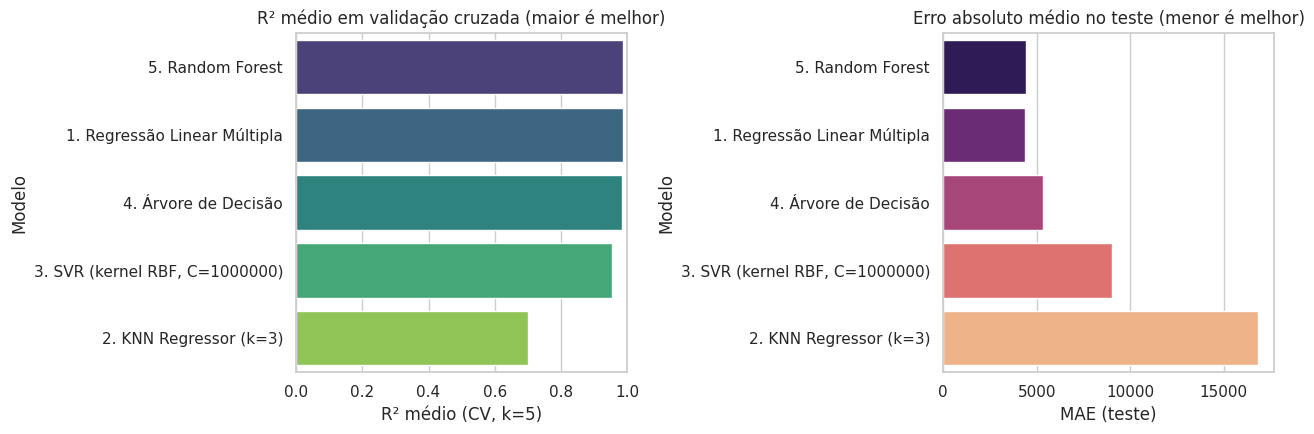

In [11]:
# =====================================================================
# 11. COMPARAÇÃO VISUAL DOS MODELOS
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=df_ranking, y="Modelo", x="R² médio (CV, k=5)", hue="Modelo", ax=axes[0], palette="viridis", legend=False)
axes[0].set_title("R² médio em validação cruzada (maior é melhor)")
axes[0].set_xlim(0, 1)

sns.barplot(data=df_ranking, y="Modelo", x="MAE (teste)", hue="Modelo", ax=axes[1], palette="magma", legend=False)
axes[1].set_title("Erro absoluto médio no teste (menor é melhor)")
plt.tight_layout()
plt.show()


Melhor modelo (por R² médio em CV): 5. Random Forest


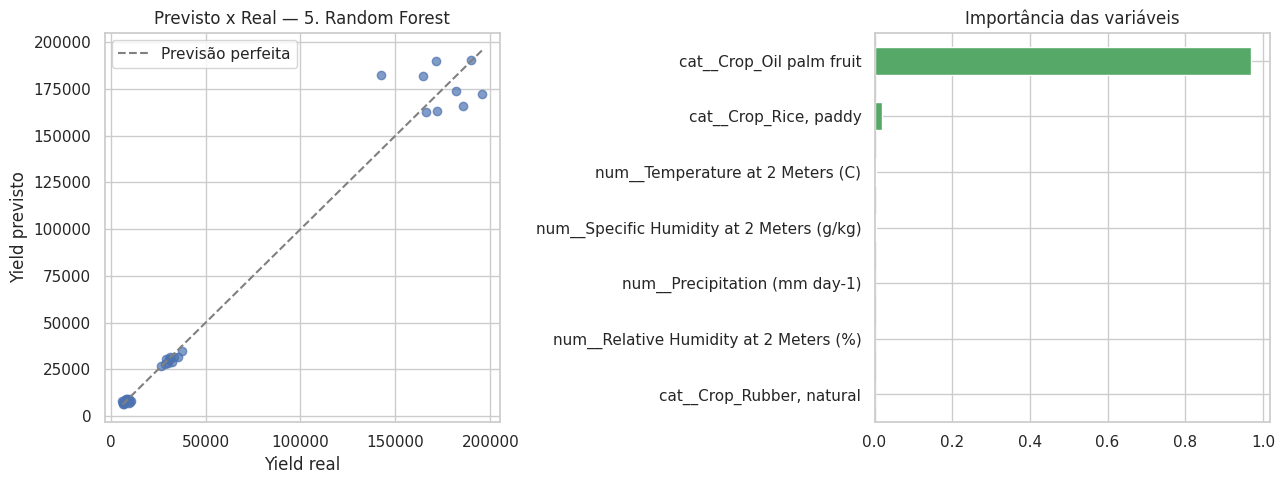

In [12]:
# =====================================================================
# 12. DIAGNÓSTICO DO MELHOR MODELO: PREVISTO x REAL E IMPORTÂNCIA DAS VARIÁVEIS
# =====================================================================
best_model_name = df_ranking.iloc[0]["Modelo"]
best_pipe, best_pred = fitted_pipelines[best_model_name]
print(f"Melhor modelo (por R² médio em CV): {best_model_name}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico Previsto x Real: quanto mais próximo da diagonal, melhor a previsão
axes[0].scatter(y_test, best_pred, alpha=0.7, color="#4C72B0")
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[0].plot(lims, lims, "--", color="gray", label="Previsão perfeita")
axes[0].set_xlabel("Yield real")
axes[0].set_ylabel("Yield previsto")
axes[0].set_title(f"Previsto x Real — {best_model_name}")
axes[0].legend()

# Importância das variáveis, quando o modelo suporta (árvore / random forest)
final_estimator = best_pipe.named_steps["model"]
feature_names = best_pipe.named_steps["prep"].get_feature_names_out()
if hasattr(final_estimator, "feature_importances_"):
    importances = pd.Series(final_estimator.feature_importances_, index=feature_names).sort_values()
    importances.plot(kind="barh", ax=axes[1], color="#55A868")
    axes[1].set_title("Importância das variáveis")
else:
    axes[1].text(0.5, 0.5, "Modelo sem\n'feature_importances_' nativo", ha="center", va="center")
    axes[1].set_axis_off()

plt.tight_layout()
plt.show()


## 3. Conclusões

**Principais achados:**
* A cultura (`Crop`) é o fator que mais determina o patamar de rendimento — tanto a clusterização quanto a importância de variáveis dos modelos de árvore confirmam isso. Ignorar essa coluna (como no rascunho original desta atividade) descartaria a informação mais relevante da base.
* Dentro de cada cultura, as variáveis climáticas (em especial precipitação e umidade) explicam parte relevante da variação do rendimento entre safras.
* O *Isolation Forest* identificou 11 safras discrepantes, concentradas nas culturas de maior variância de rendimento (*Oil palm fruit* e *Rice paddy*), indicando pontos que merecem verificação adicional.
* Entre os cinco algoritmos testados, **Random Forest** (R² 0,9880), **Regressão Linear Múltipla** (0,9870) e **Árvore de Decisão** (0,9862) ficaram praticamente empatados no topo, os três acima de 0,98 de R² médio em validação cruzada. O **SVR** chegou a 0,9552 — um resultado competitivo, mas alcançado apenas após a seleção do hiperparâmetro `C` por validação cruzada: com os valores padrão o algoritmo praticamente não aprendia, pois a escala muito ampla do `Yield` (de ~5 mil a ~200 mil) prejudica sua otimização. O **KNN** foi o único com desempenho claramente inferior (0,6995), o que é coerente com um método baseado em distância operando sobre um alvo de escala tão heterogênea entre as culturas.

**Pontos fortes do trabalho:**
* Uso de `Pipeline` + `ColumnTransformer`, evitando vazamento de dados entre treino e teste;
* Escolha de hiperparâmetros (k do KNN, C do SVR, k do KMeans) orientada por validação cruzada / métricas, e não arbitrária;
* Combinação de métricas de erro (MAE, RMSE) com métricas de ajuste (R²) e validação cruzada, dando uma visão mais robusta do desempenho do que uma única divisão treino/teste.

**Limitações:**
* A base é pequena (156 registros, 39 por cultura), o que limita a capacidade de generalização dos modelos e torna as métricas sensíveis à divisão treino/teste escolhida — por isso a validação cruzada foi usada como complemento;
* Não há variáveis de solo, manejo agrícola ou insumos (adubação, irrigação, pragas), que provavelmente têm forte influência no rendimento real e não estão disponíveis nesta base;
* As quatro culturas têm faixas de rendimento tão diferentes que um único modelo global pode ser menos preciso do que modelos específicos por cultura — uma extensão natural deste trabalho seria comparar o modelo global com modelos treinados separadamente para cada cultura.
